In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print("TensorFlow version:", tf.__version__)
print("GPU Available:", len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow version: 2.21.0
GPU Available: False


In [2]:
# Load Fashion-MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Display original shapes
print("Original Training Images:", x_train.shape)
print("Original Training Labels:", y_train.shape)

print("Original Testing Images:", x_test.shape)
print("Original Testing Labels:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original Training Images: (60000, 28, 28)
Original Training Labels: (60000,)
Original Testing Images: (10000, 28, 28)
Original Testing Labels: (10000,)


In [3]:
# Normalize pixel values to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Prepare data for MLP
x_train_mlp = x_train
x_test_mlp = x_test

# Prepare data for CNN
x_train_cnn = np.expand_dims(x_train, axis=-1)
x_test_cnn = np.expand_dims(x_test, axis=-1)

# Print shapes
print("MLP Training Shape:", x_train_mlp.shape)
print("MLP Testing Shape:", x_test_mlp.shape)

print("CNN Training Shape:", x_train_cnn.shape)
print("CNN Testing Shape:", x_test_cnn.shape)

MLP Training Shape: (60000, 28, 28)
MLP Testing Shape: (10000, 28, 28)
CNN Training Shape: (60000, 28, 28, 1)
CNN Testing Shape: (10000, 28, 28, 1)


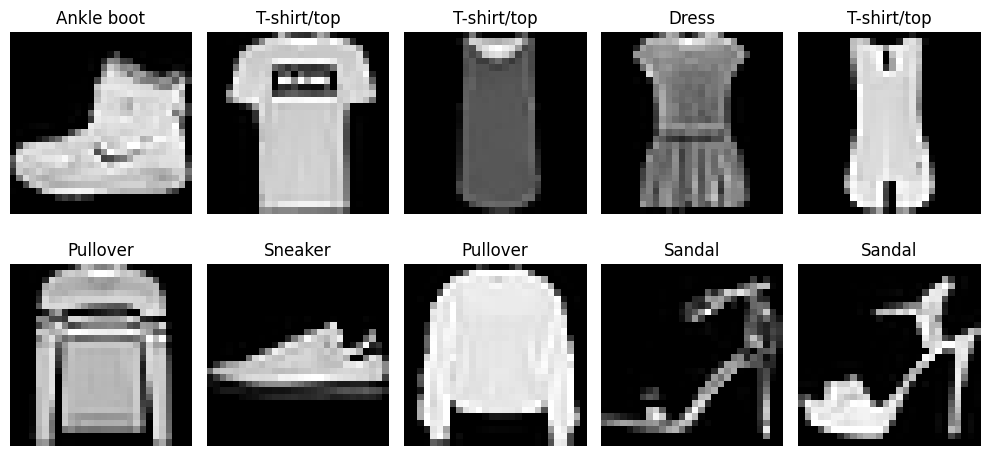

In [4]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
# Build MLP model
mlp_model = models.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

# Compile MLP model
mlp_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display model summary
print("MLP Model Summary:")
mlp_model.summary()

MLP Model Summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Build CNN model
cnn_model = models.Sequential([
    keras.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        filters=16,
        kernel_size=(3, 3),
        activation='relu'
    ),

    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation='relu'
    ),

    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),

    layers.Dense(64, activation='relu'),

    layers.Dense(10, activation='softmax')
])

# Compile CNN model
cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display model summary
print("CNN Model Summary:")
cnn_model.summary()

CNN Model Summary:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Train MLP model
history_mlp = mlp_model.fit(
    x_train_mlp,
    y_train,
    validation_split=0.1,
    epochs=5,
    batch_size=64,
    verbose=2
)

Epoch 1/5
844/844 - 6s - 7ms/step - accuracy: 0.8245 - loss: 0.4963 - val_accuracy: 0.8540 - val_loss: 0.3915
Epoch 2/5
844/844 - 6s - 7ms/step - accuracy: 0.8672 - loss: 0.3650 - val_accuracy: 0.8698 - val_loss: 0.3572
Epoch 3/5
844/844 - 4s - 5ms/step - accuracy: 0.8792 - loss: 0.3291 - val_accuracy: 0.8750 - val_loss: 0.3431
Epoch 4/5
844/844 - 4s - 5ms/step - accuracy: 0.8879 - loss: 0.3028 - val_accuracy: 0.8803 - val_loss: 0.3371
Epoch 5/5
844/844 - 7s - 8ms/step - accuracy: 0.8956 - loss: 0.2823 - val_accuracy: 0.8795 - val_loss: 0.3280


In [8]:
# Train CNN model
history_cnn = cnn_model.fit(
    x_train_cnn,
    y_train,
    validation_split=0.1,
    epochs=5,
    batch_size=64,
    verbose=2
)

Epoch 1/5
844/844 - 25s - 29ms/step - accuracy: 0.8013 - loss: 0.5534 - val_accuracy: 0.8588 - val_loss: 0.3876
Epoch 2/5
844/844 - 23s - 27ms/step - accuracy: 0.8680 - loss: 0.3658 - val_accuracy: 0.8737 - val_loss: 0.3558
Epoch 3/5
844/844 - 22s - 26ms/step - accuracy: 0.8839 - loss: 0.3233 - val_accuracy: 0.8818 - val_loss: 0.3226
Epoch 4/5
844/844 - 42s - 50ms/step - accuracy: 0.8928 - loss: 0.2967 - val_accuracy: 0.8912 - val_loss: 0.2937
Epoch 5/5
844/844 - 21s - 25ms/step - accuracy: 0.8983 - loss: 0.2765 - val_accuracy: 0.8893 - val_loss: 0.2898


In [9]:
# Evaluate MLP
mlp_test_loss, mlp_test_acc = mlp_model.evaluate(
    x_test_mlp,
    y_test,
    verbose=0
)

# Evaluate CNN
cnn_test_loss, cnn_test_acc = cnn_model.evaluate(
    x_test_cnn,
    y_test,
    verbose=0
)

# Display results
print("MLP Test Results:")
print(f"Accuracy: {mlp_test_acc:.4f}")
print(f"Loss: {mlp_test_loss:.4f}")

print("\nCNN Test Results:")
print(f"Accuracy: {cnn_test_acc:.4f}")
print(f"Loss: {cnn_test_loss:.4f}")

MLP Test Results:
Accuracy: 0.8745
Loss: 0.3516

CNN Test Results:
Accuracy: 0.8873
Loss: 0.3098


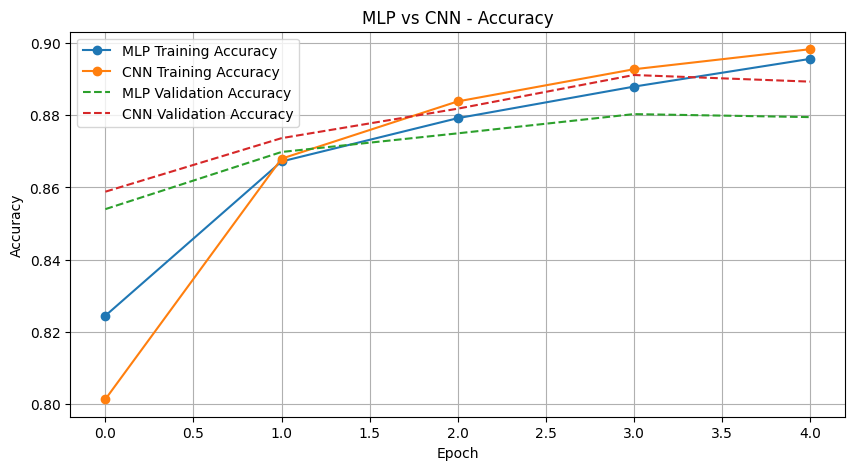

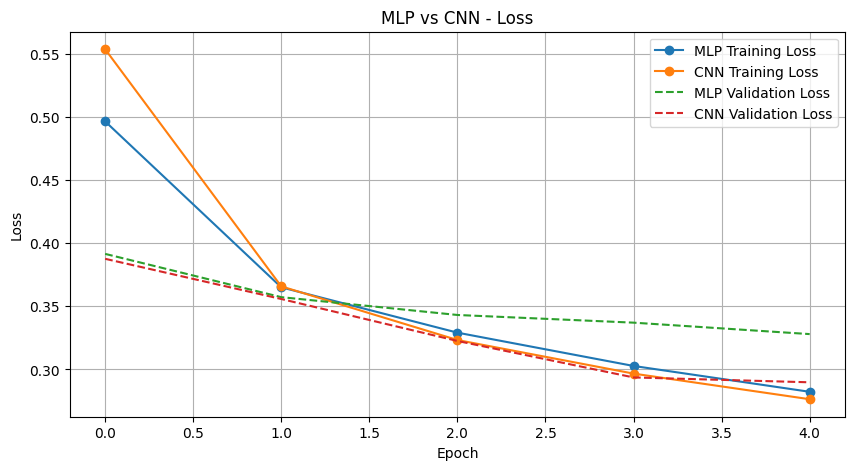

In [10]:
# Accuracy comparison
plt.figure(figsize=(10, 5))

plt.plot(
    history_mlp.history['accuracy'],
    marker='o',
    label='MLP Training Accuracy'
)

plt.plot(
    history_cnn.history['accuracy'],
    marker='o',
    label='CNN Training Accuracy'
)

plt.plot(
    history_mlp.history['val_accuracy'],
    linestyle='--',
    label='MLP Validation Accuracy'
)

plt.plot(
    history_cnn.history['val_accuracy'],
    linestyle='--',
    label='CNN Validation Accuracy'
)

plt.title('MLP vs CNN - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()


# Loss comparison
plt.figure(figsize=(10, 5))

plt.plot(
    history_mlp.history['loss'],
    marker='o',
    label='MLP Training Loss'
)

plt.plot(
    history_cnn.history['loss'],
    marker='o',
    label='CNN Training Loss'
)

plt.plot(
    history_mlp.history['val_loss'],
    linestyle='--',
    label='MLP Validation Loss'
)

plt.plot(
    history_cnn.history['val_loss'],
    linestyle='--',
    label='CNN Validation Loss'
)

plt.title('MLP vs CNN - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

In [11]:
mlp_params = mlp_model.count_params()
cnn_params = cnn_model.count_params()

print("MLP Trainable Parameters:", f"{mlp_params:,}")
print("CNN Trainable Parameters:", f"{cnn_params:,}")

MLP Trainable Parameters: 235,146
CNN Trainable Parameters: 56,714


In [12]:
# Save models
mlp_model.save("mlp_model.h5")
cnn_model.save("cnn_model.h5")

# Calculate model sizes in MB
mlp_size_mb = os.path.getsize("mlp_model.h5") / (1024 ** 2)
cnn_size_mb = os.path.getsize("cnn_model.h5") / (1024 ** 2)

print(f"MLP Model Size: {mlp_size_mb:.4f} MB")
print(f"CNN Model Size: {cnn_size_mb:.4f} MB")

MLP Model Size: 2.7217 MB
CNN Model Size: 0.6874 MB


In [13]:
# MLP FLOPs
def estimate_flops_mlp(input_dim, hidden_dims, output_dim):
    flops = 0
    prev_dim = input_dim

    for h in hidden_dims:
        flops += 2 * prev_dim * h
        prev_dim = h

    flops += 2 * prev_dim * output_dim

    return flops


# CNN FLOPs
def estimate_flops_cnn():

    # First Conv2D
    conv1 = 26 * 26 * 16 * 3 * 3 * 1

    # Second Conv2D
    conv2 = 11 * 11 * 32 * 3 * 3 * 16

    # First Dense
    dense1 = 800 * 64

    # Output Dense
    dense2 = 64 * 10

    total_macs = conv1 + conv2 + dense1 + dense2

    return 2 * total_macs


# Calculate inference FLOPs
flops_mlp_inf = estimate_flops_mlp(
    784, [256, 128], 10
)

flops_cnn_inf = estimate_flops_cnn()

print(f"MLP Inference FLOPs: {flops_mlp_inf:,}")
print(f"CNN Inference FLOPs: {flops_cnn_inf:,}")

print(f"MLP: {flops_mlp_inf / 1e6:.2f} MFLOPs")
print(f"CNN: {flops_cnn_inf / 1e6:.2f} MFLOPs")

MLP Inference FLOPs: 469,504
CNN Inference FLOPs: 1,413,504
MLP: 0.47 MFLOPs
CNN: 1.41 MFLOPs


In [14]:
# Approximate training FLOPs
flops_mlp_train = 3 * flops_mlp_inf
flops_cnn_train = 3 * flops_cnn_inf

print("MLP Training FLOPs:", f"{flops_mlp_train:,}")
print("CNN Training FLOPs:", f"{flops_cnn_train:,}")

print(f"MLP Training: {flops_mlp_train / 1e6:.2f} MFLOPs")
print(f"CNN Training: {flops_cnn_train / 1e6:.2f} MFLOPs")

MLP Training FLOPs: 1,408,512
CNN Training FLOPs: 4,240,512
MLP Training: 1.41 MFLOPs
CNN Training: 4.24 MFLOPs


In [15]:
# Estimate training memory in MB
mem_mlp_train_mb = mlp_params * 16 / (1024 ** 2)
mem_cnn_train_mb = cnn_params * 16 / (1024 ** 2)

print(f"MLP Training Memory: {mem_mlp_train_mb:.2f} MB")
print(f"CNN Training Memory: {mem_cnn_train_mb:.2f} MB")

MLP Training Memory: 3.59 MB
CNN Training Memory: 0.87 MB


In [16]:
results = pd.DataFrame({
    "Model": ["MLP", "CNN"],

    "Test Accuracy": [
        mlp_test_acc,
        cnn_test_acc
    ],

    "Test Loss": [
        mlp_test_loss,
        cnn_test_loss
    ],

    "Trainable Parameters": [
        mlp_params,
        cnn_params
    ],

    "Saved Model Size (MB)": [
        mlp_size_mb,
        cnn_size_mb
    ],

    "FLOPs (Training)": [
        f"{flops_mlp_train / 1e6:.2f}M",
        f"{flops_cnn_train / 1e6:.2f}M"
    ],

    "FLOPs (Inference)": [
        f"{flops_mlp_inf / 1e6:.2f}M",
        f"{flops_cnn_inf / 1e6:.2f}M"
    ],

    "Training Memory (MB)": [
        f"{mem_mlp_train_mb:.2f}",
        f"{mem_cnn_train_mb:.2f}"
    ]
})

display(results.round(4))

,Model,Test Accuracy,Test Loss,Trainable Parameters,Saved Model Size (MB),FLOPs (Training),FLOPs (Inference),Training Memory (MB)
0,MLP,0.8745,0.3516,235146,2.7217,1.41M,0.47M,3.59
1,CNN,0.8873,0.3098,56714,0.6874,4.24M,1.41M,0.87


In [17]:
print("FINAL COMPARISON")
print("================")

if cnn_test_acc > mlp_test_acc:
    print("CNN achieved higher test accuracy.")
else:
    print("MLP achieved higher test accuracy.")

if cnn_params < mlp_params:
    print("CNN has fewer trainable parameters.")
else:
    print("MLP has fewer trainable parameters.")

if cnn_size_mb < mlp_size_mb:
    print("CNN has a smaller saved model size.")
else:
    print("MLP has a smaller saved model size.")

print("\nConclusion:")
print(
    "CNN is generally more suitable for image classification "
    "because it extracts spatial features and preserves "
    "the relationships between image pixels."
)

print(
    "MLP is simpler and requires fewer computational operations "
    "during inference, but it does not exploit spatial "
    "information as effectively as CNN."
)

FINAL COMPARISON
CNN achieved higher test accuracy.
CNN has fewer trainable parameters.
CNN has a smaller saved model size.

Conclusion:
CNN is generally more suitable for image classification because it extracts spatial features and preserves the relationships between image pixels.
MLP is simpler and requires fewer computational operations during inference, but it does not exploit spatial information as effectively as CNN.
